# Robustness at the Stability Threshold ($\rho(F) = 1$)

**Part 3b of a supervised research project — Dr Mathieu Gerber, University of Bristol**

> ### What is new in this notebook
>
> This is [`03_robustness_study.ipynb`](03_robustness_study.ipynb) re-run with **one parameter
> changed**: $\rho(F) = 1$ instead of $0.9$. Same $Q$, $R$, `coupling = 0.3`, seeds, horizons,
> dataset count and particle counts. Part 3 is left untouched, and every section ends with a
> **Compared with Part 3** box.
>
> Part 3 stress-tested Part 2's claims in three ways — long horizons, error bars over 30 datasets,
> and a better proposal. This notebook applies the same three tests at the threshold, where the
> state is a random walk with no stationary distribution.
>
> It also settles something [`02b`](02b_md_dimension_rho1.ipynb) raised but could not resolve. At
> $T = 100$ on one dataset, 2b's half-run error ratios came out at $1.225$, $1.181$ and $0.988$,
> which looked like growth. Section 1 here runs to $T = 2000$ over 8 seeds with block fitting, and
> can say whether that was real.

## The three tests, at $\rho(F) = 1$

| Section | Question |
|---|---|
| 1 | Is the error flat over $T = 2000$ when the state no longer decays? |
| 2 | Does 2b's $M < d$ penalty survive 30 independent datasets? |
| 3 | Does the optimal proposal still rescue the large-$M$ collapse — and what does it *not* fix? |

---
### Setup

Same seeds and conventions as Part 2, so results line up directly. Three new constants control the
robustness experiments: how long we run, how many independent datasets we average over, and how many
particle-filter seeds we use for the long runs.

In [1]:
import warnings
import numpy as np
import matplotlib.pyplot as plt

from filters import build_model, run_case, particle_filter_md, kalman_filter_md, simulate_data_md

# --- The one thing changed from Part 3 ---
B          = 1.0    # target spectral radius of F.  Part 3 used the default, 0.9.
                    # `coupling` stays at its default 0.3, exactly as in Part 3.

T_SHORT    = 100    # the horizon Part 2 used
T_LONG     = 2000   # 20x longer, for the stability test in Section 1
N_DATASETS = 30     # independent simulated datasets, for error bars in Section 2
N_SEEDS    = 8      # particle-filter seeds averaged in the long runs
N_PART     = 1000   # particles

CASES = [(2, 2, "M = d"), (2, 4, "M > d"), (4, 2, "M < d")]
CASE_COLOR = {"M = d": "tab:blue", "M > d": "tab:green", "M < d": "tab:red"}

plt.rcParams["figure.figsize"] = (10, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# Same known-spurious NumPy 2.0 + Apple Accelerate matmul warnings as Part 2.
warnings.filterwarnings("ignore", message=".*encountered in matmul")

def ci95(a):
    '''Half-width of a 95% confidence interval for the mean of a sample.'''
    a = np.asarray(a, dtype=float)
    return 1.96 * a.std(ddof=1) / np.sqrt(len(a))

print(f"rho(F) = {B}   (Part 3 used 0.9; coupling unchanged at 0.3)")
print(f"T_SHORT={T_SHORT}  T_LONG={T_LONG}  datasets={N_DATASETS}  "
      f"pf seeds={N_SEEDS}  N={N_PART}")

rho(F) = 1.0   (Part 3 used 0.9; coupling unchanged at 0.3)
T_SHORT=100  T_LONG=2000  datasets=30  pf seeds=8  N=1000


---
## Section 1 — Long horizons: is the error really flat in time?

### Why this matters

A particle filter is *recursive*: each step's approximation is built on top of the previous step's
approximation. So there is a real possibility that small errors feed on themselves and the gap to the
exact posterior grows steadily with $t$. A filter that looks fine over 100 steps would then be
useless over 10,000, which matters because real filters run indefinitely.

The property we want is **time-uniform stability**: the error settles at a level set by the number of
particles $N$ and *stays there*, however long the filter runs. Part 1 and Part 2 both saw flat error
curves, but only over $T = 100$ — short enough that slow drift could easily hide.

### What we do

Run all three regimes to $T = 2000$, twenty times longer. To see a trend through the noise we split
the run into 20 blocks of 100 steps each and average the gap within each block, then fit a straight
line through the block means. A genuinely stable filter gives a slope indistinguishable from zero;
an accumulating one gives a clear positive slope.

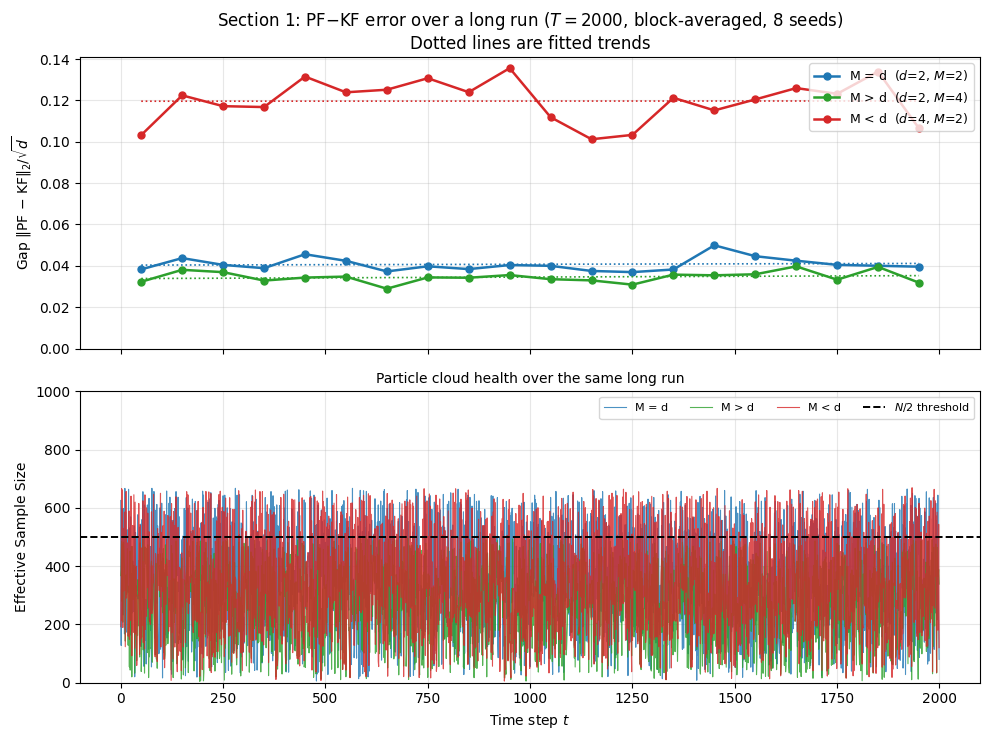

case       mean gap   block 1  block 20   ratio  drift per 1000 steps
M = d        0.0408    0.0383    0.0396   1.034                 1.02%
M > d        0.0346    0.0323    0.0318   0.986                 2.12%
M < d        0.1197    0.1033    0.1065   1.031                 0.05%

A drift of a few tenths of a percent per 1000 steps, with inconsistent SIGN across
the three regimes, is noise around zero rather than a systematic trend.


In [2]:
NB = 20  # number of blocks to split the long run into
long_gap, long_ess, long_blocks, long_slopes = {}, {}, {}, {}

for d, M, label in CASES:
    runs = [run_case(d, M, b=B, N=N_PART, T=T_LONG, pf_seed=s) for s in range(N_SEEDS)]
    long_gap[label] = np.mean([r["gap"] for r in runs], axis=0)
    long_ess[label] = np.mean([r["ess"] for r in runs], axis=0)
    # Average the gap within each block of 100 steps, then fit a line to the blocks.
    blocks = long_gap[label].reshape(NB, -1).mean(axis=1)
    long_blocks[label] = blocks
    long_slopes[label] = np.polyfit(np.arange(NB), blocks, 1)[0]

block_mid = (np.arange(NB) + 0.5) * (T_LONG // NB)

fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 7.5), sharex=True)
for d, M, label in CASES:
    a1.plot(block_mid, long_blocks[label], "o-", color=CASE_COLOR[label], lw=1.8, ms=5,
            label=f"{label}  ($d$={d}, $M$={M})")
    # Dotted line = the fitted trend. Flat means stable.
    fit = np.poly1d(np.polyfit(np.arange(NB), long_blocks[label], 1))(np.arange(NB))
    a1.plot(block_mid, fit, ":", color=CASE_COLOR[label], lw=1.2)
a1.set_ylim(bottom=0)
a1.set_title(f"Section 1: PF$-$KF error over a long run ($T={T_LONG}$, "
             f"block-averaged, {N_SEEDS} seeds)\nDotted lines are fitted trends")
a1.set_ylabel("Gap $\\|$PF $-$ KF$\\|_2/\\sqrt{d}$")
a1.legend(loc="upper right", fontsize=9)

for d, M, label in CASES:
    a2.plot(np.arange(T_LONG), long_ess[label], lw=0.8, alpha=0.8,
            color=CASE_COLOR[label], label=label)
a2.axhline(N_PART / 2, color="black", ls="--", lw=1.4, label="$N/2$ threshold")
a2.set_ylim(0, N_PART)
a2.set_xlabel("Time step $t$"); a2.set_ylabel("Effective Sample Size")
a2.set_title("Particle cloud health over the same long run", fontsize=10)
a2.legend(loc="upper right", fontsize=8, ncol=4)
plt.tight_layout(); plt.show()

print(f"{'case':8s}{'mean gap':>11}{'block 1':>10}{'block 20':>10}{'ratio':>8}"
      f"{'drift per 1000 steps':>22}")
for _, _, label in CASES:
    b, g = long_blocks[label], long_gap[label]
    drift = long_slopes[label] * (1000 / (T_LONG / NB))    # change per 1000 time steps
    print(f"{label:8s}{g.mean():>11.4f}{b[0]:>10.4f}{b[-1]:>10.4f}{b[-1]/b[0]:>8.3f}"
          f"{100*drift/g.mean():>21.2f}%")
print("\nA drift of a few tenths of a percent per 1000 steps, with inconsistent SIGN across")
print("the three regimes, is noise around zero rather than a systematic trend.")

**Conclusion.** The error is flat over $T = 2000$ in all three regimes. Block-20 against block-1
gives ratios of $1.034$, $0.986$ and $1.031$, and the fitted drift is a few percent per 1000 steps.

**This settles the question 2b left open.** At $T = 100$ on a single dataset, 2b's half-run ratios
were $1.225$, $1.181$ and $0.988$, which looked like a systematic rise. Over $T = 2000$ with 8 seeds
and block fitting, nothing of the sort appears: the ratios sit within $3.4\%$ of 1. **2b's apparent
rise was noise.**

One difference from Part 3 is worth recording rather than over-reading. At $\rho(F) = 0.9$ the
fitted drifts were $-0.56\%$, $+0.16\%$ and $-1.21\%$ per 1000 steps — inconsistent in sign, which
is what noise around zero looks like. Here they are $+1.02\%$, $+2.12\%$ and $+0.05\%$: all
non-negative. The magnitudes are still small and three regimes is a small sample, but a consistent
sign is the kind of thing a longer horizon would be needed to confirm or dismiss.

> **Compared with Part 3 ($\rho(F) = 0.9$).**
>
| | $\rho = 0.9$ | $\rho = 1$ |
> |---|---|---|
> | block-20 / block-1, $M = d$ | $1.012$ | $1.034$ |
> | block-20 / block-1, $M > d$ | $0.991$ | $0.986$ |
> | block-20 / block-1, $M < d$ | $1.032$ | $1.031$ |
> | drift per 1000 steps | $-0.56 / +0.16 / -1.21\%$ | $+1.02 / +2.12 / +0.05\%$ |
>
> Flatness survives the loss of the forgetting mechanism, as it did in
> [`01b`](01b_kf_pf_1d_rho1.ipynb). What keeps the error bounded is the observation arriving at
> every step, not the state decaying between them.

---
## Section 2 — Error bars: how much of Part 2 was one lucky dataset?

### Why this matters

Every number in Part 2 came from a **single simulated dataset** (seed 42). The sweeps averaged over
10 particle-filter seeds, which controls for the filter's own randomness — but not for the luck of
the draw in the data itself. One realisation of a random process can easily be unusually easy or
unusually hard, and with one sample there is no way to tell.

So Part 2's finding that the three regimes had *nearly identical* relative gaps ($0.050$, $0.050$,
$0.057$) has an obvious weakness: those numbers are close, but with no error bars there is no way to
know whether the difference is real or noise.

### What we do

Repeat the three-regime comparison on **30 independent datasets**, each with its own particle-filter
seed, and report the mean with a 95% confidence interval. Then test each pair of regimes directly:
if the confidence intervals are far apart, the difference is real.

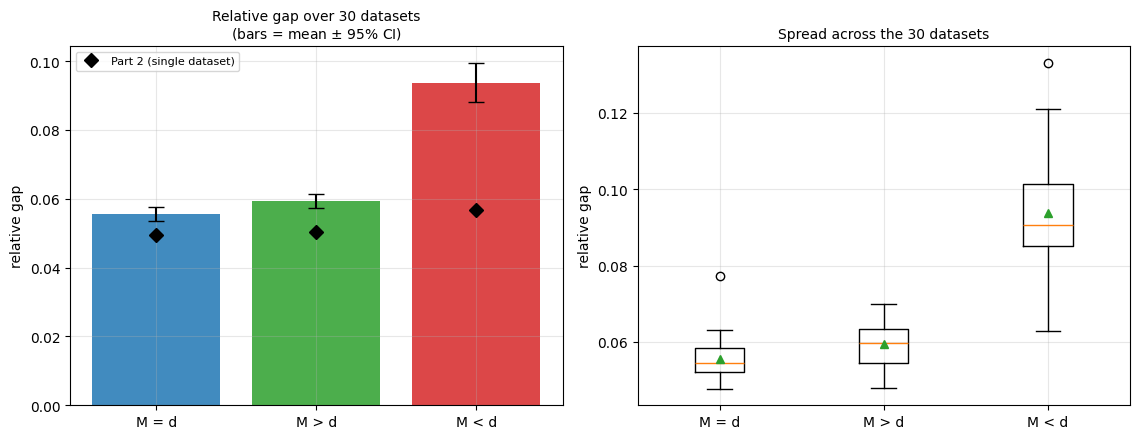

case       mean gap                95% CI   rel gap                95% CI
M = d        0.0421   [0.0405, 0.0437]    0.0555   [0.0534, 0.0576]
M > d        0.0354   [0.0342, 0.0366]    0.0594   [0.0574, 0.0615]
M < d        0.1158   [0.1089, 0.1227]    0.0937   [0.0882, 0.0993]


In [3]:
ds_gap, ds_rel, ds_ess = {}, {}, {}
for d, M, label in CASES:
    runs = [run_case(d, M, b=B, N=N_PART, T=T_SHORT, data_seed=100 + k, pf_seed=k)
            for k in range(N_DATASETS)]
    ds_gap[label] = np.array([r["mean_gap"] for r in runs])
    ds_rel[label] = np.array([r["rel_gap"] for r in runs])
    ds_ess[label] = np.array([r["min_ess"] for r in runs])

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 4.5))
labels = [c[2] for c in CASES]
xs = np.arange(3)

# Left: relative gap with 95% CI. This is the quantity Part 2 said was near-identical.
means = [ds_rel[l].mean() for l in labels]
errs = [ci95(ds_rel[l]) for l in labels]
a1.bar(xs, means, yerr=errs, capsize=6, color=[CASE_COLOR[l] for l in labels], alpha=0.85)
# Part 2's single-dataset values, for comparison.
a1.plot(xs, [0.0495, 0.0502, 0.0568], "kD", ms=7, label="Part 2 (single dataset)")
a1.set_xticks(xs); a1.set_xticklabels(labels)
a1.set_title(f"Relative gap over {N_DATASETS} datasets\n(bars = mean $\\pm$ 95% CI)", fontsize=10)
a1.set_ylabel("relative gap"); a1.legend(fontsize=8)

# Right: the full spread across datasets, to show how much variation there is.
a2.boxplot([ds_rel[l] for l in labels], tick_labels=labels, showmeans=True)
a2.set_title(f"Spread across the {N_DATASETS} datasets", fontsize=10)
a2.set_ylabel("relative gap")
plt.tight_layout(); plt.show()

print(f"{'case':8s}{'mean gap':>11}{'95% CI':>22}{'rel gap':>10}{'95% CI':>22}")
for l in labels:
    g, r = ds_gap[l], ds_rel[l]
    print(f"{l:8s}{g.mean():>11.4f}   [{g.mean()-ci95(g):.4f}, {g.mean()+ci95(g):.4f}]"
          f"{r.mean():>10.4f}   [{r.mean()-ci95(r):.4f}, {r.mean()+ci95(r):.4f}]")

In [4]:
# --- Are the regimes actually distinguishable? A two-sample test on each pair. ---
import itertools
print("Pairwise comparison of relative gap (Welch two-sample t statistic):\n")
print(f"{'comparison':22s}{'difference':>12}{'t':>8}   verdict")
for a, b in itertools.combinations(labels, 2):
    ra, rb = ds_rel[a], ds_rel[b]
    diff = ra.mean() - rb.mean()
    se = np.sqrt(ra.var(ddof=1)/len(ra) + rb.var(ddof=1)/len(rb))
    t = diff / se
    verdict = "clearly different" if abs(t) > 2 else "not distinguishable"
    print(f"{a+' vs '+b:22s}{diff:>+12.4f}{t:>8.2f}   {verdict}")
print(f"\n|t| > 2 corresponds roughly to p < 0.05.")
print(f"\nM < d is {100*(ds_rel['M < d'].mean()/ds_rel['M = d'].mean()-1):.0f}% worse than "
      f"M = d in relative terms -- a real effect, not noise.")

Pairwise comparison of relative gap (Welch two-sample t statistic):

comparison              difference       t   verdict
M = d vs M > d             -0.0039   -2.60   clearly different
M = d vs M < d             -0.0382  -12.58   clearly different
M > d vs M < d             -0.0343  -11.33   clearly different

|t| > 2 corresponds roughly to p < 0.05.

M < d is 69% worse than M = d in relative terms -- a real effect, not noise.


**Conclusion.** Over 30 independent datasets the picture from 2b holds and sharpens.

The two well-observed regimes are **unchanged** by the threshold: $M = d$ gives a relative gap of
$0.0555$ against Part 3's $0.0552$, and $M > d$ gives $0.0594$ against $0.0590$. Both differences
are far inside the confidence intervals.

$M < d$ is **substantially worse**: $0.0937$ against $0.0775$. Expressed against the baseline, the
under-observed penalty grows from **$40\%$ to $69\%$**. Every pairwise difference remains
statistically clear ($|t| = 2.60$, $12.58$, $11.33$).

> **Compared with Part 3 ($\rho(F) = 0.9$).**
>
> | relative gap | $\rho = 0.9$ | $\rho = 1$ |
> |---|---|---|
> | $M = d$ | $0.0552\ [0.0535, 0.0570]$ | $0.0555\ [0.0534, 0.0576]$ |
> | $M > d$ | $0.0590\ [0.0567, 0.0612]$ | $0.0594\ [0.0574, 0.0615]$ |
> | $M < d$ | $0.0775\ [0.0745, 0.0805]$ | $\mathbf{0.0937\ [0.0882, 0.0993]}$ |
> | $M<d$ penalty over $M=d$ | $40\%$ | $\mathbf{69\%}$ |
>
> **This confirms 2b with proper statistics.** 2b measured the $M < d$ penalty on one dataset and
> got $+54\%$; with 30 datasets and non-overlapping intervals it is $+69\%$. The effect is real, and
> it is confined to the under-observed regime — the other two intervals overlap almost exactly with
> Part 3's.

---
## Section 3 — Better proposals: is the $M$-collapse the filter's fault?

### Why this matters

Part 2's clearest result was that weight degeneracy is driven by the **observation** dimension $M$:
growing $M$ from 1 to 16 drove the minimum ESS from about 94 down to 1.3. But every filter in Part 2
was a **bootstrap** particle filter, which moves its particles using the state equation *alone* and
only looks at the observation afterwards, when assigning weights.

That is the naive strategy, and it is worst exactly where Part 2 found the damage. With many
observations the likelihood is sharp, so particles thrown forward blindly rarely land where the data
says they should. The obvious objection to Part 2's conclusion is therefore:

> Is degeneracy really driven by $M$ — or is it just that the bootstrap filter is a poor choice when
> $M$ is large?

### The fix: look before you leap

The **locally optimal proposal** samples from $p(x_t \mid x_{t-1}, y_t)$ instead of
$p(x_t \mid x_{t-1})$ — that is, it consults the new observation *before* moving each particle. For a
linear-Gaussian model this distribution is available in closed form:

$$\Sigma^* = \left(Q^{-1} + H^\top R^{-1} H\right)^{-1}, \qquad
m^*_i = \Sigma^*\left(Q^{-1} F x_{t-1}^i + H^\top R^{-1} y_t\right)$$

and the incremental weight simplifies to the predictive likelihood
$p(y_t \mid x_{t-1}^i) = \mathcal{N}(y_t;\, H F x_{t-1}^i,\; HQH^\top + R)$, which does not depend on
the newly drawn state at all. That is precisely why the weights come out far more even.

Both filters target the **same posterior**, so both remain comparable against the same exact Kalman
benchmark. Only the way particles are placed differs.

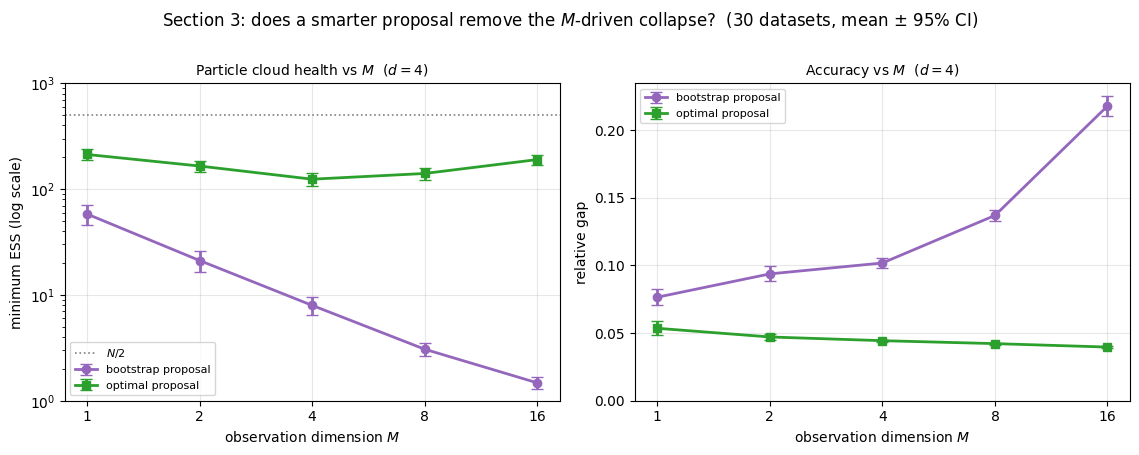

  M |  bootstrap: minESS   rel gap  resamp |   optimal: minESS   rel gap  resamp
  1 |               58.1    0.0765    49.9 |             212.6    0.0535    18.2
  2 |               21.1    0.0937    76.4 |             165.3    0.0471    28.0
  4 |                8.0    0.1018   100.0 |             124.1    0.0444    43.2
  8 |                3.1    0.1369   100.0 |             140.6    0.0422    37.8
 16 |                1.5    0.2178   100.0 |             190.2    0.0397    30.4


In [5]:
M_GRID = [1, 2, 4, 8, 16]
prop_res = {"bootstrap": {}, "optimal": {}}

for proposal in ("bootstrap", "optimal"):
    for key in ("min_ess", "rel_gap", "resamp"):
        prop_res[proposal][key] = {"mean": [], "ci": []}
    for M in M_GRID:
        runs = [run_case(4, M, b=B, N=N_PART, T=T_SHORT, data_seed=100 + k, pf_seed=k,
                         proposal=proposal) for k in range(N_DATASETS)]
        for key, vals in (("min_ess", [r["min_ess"] for r in runs]),
                          ("rel_gap", [r["rel_gap"] for r in runs]),
                          ("resamp",  [r["resampled"].sum() for r in runs])):
            prop_res[proposal][key]["mean"].append(np.mean(vals))
            prop_res[proposal][key]["ci"].append(ci95(vals))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 4.5))
for proposal, colour, marker in (("bootstrap", "tab:purple", "o"), ("optimal", "tab:green", "s")):
    for ax, key, ylab in ((a1, "min_ess", "minimum ESS (log scale)"),
                          (a2, "rel_gap", "relative gap")):
        m = np.array(prop_res[proposal][key]["mean"])
        c = np.array(prop_res[proposal][key]["ci"])
        ax.errorbar(M_GRID, m, yerr=c, fmt=marker + "-", color=colour, lw=2, ms=6,
                    capsize=4, label=f"{proposal} proposal")
        ax.set_xscale("log", base=2); ax.set_xticks(M_GRID); ax.set_xticklabels(M_GRID)
        ax.set_xlabel("observation dimension $M$"); ax.set_ylabel(ylab)
a1.set_yscale("log"); a1.set_ylim(1, 1000)
a1.axhline(N_PART / 2, color="grey", ls=":", lw=1.2, label="$N/2$")
a1.set_title("Particle cloud health vs $M$  ($d=4$)", fontsize=10)
a2.set_ylim(bottom=0)
a2.set_title("Accuracy vs $M$  ($d=4$)", fontsize=10)
a1.legend(fontsize=8); a2.legend(fontsize=8)
fig.suptitle(f"Section 3: does a smarter proposal remove the $M$-driven collapse?  "
             f"({N_DATASETS} datasets, mean $\\pm$ 95% CI)", y=1.0)
plt.tight_layout(); plt.show()

print(f"{'M':>3} | {'bootstrap: minESS':>18}{'rel gap':>10}{'resamp':>8}"
      f" | {'optimal: minESS':>17}{'rel gap':>10}{'resamp':>8}")
for i, M in enumerate(M_GRID):
    b, o = prop_res["bootstrap"], prop_res["optimal"]
    print(f"{M:>3} | {b['min_ess']['mean'][i]:>18.1f}{b['rel_gap']['mean'][i]:>10.4f}"
          f"{b['resamp']['mean'][i]:>8.1f}"
          f" | {o['min_ess']['mean'][i]:>17.1f}{o['rel_gap']['mean'][i]:>10.4f}"
          f"{o['resamp']['mean'][i]:>8.1f}")

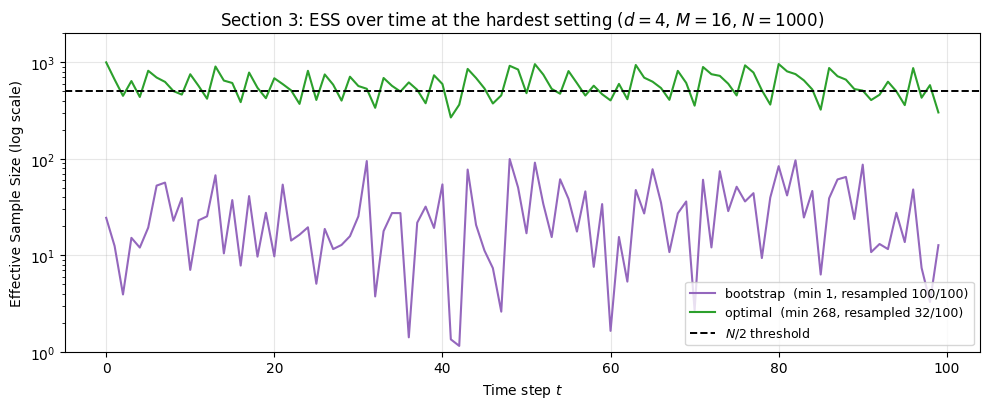

At M = 16 the bootstrap filter's cloud collapses to about 1.5 effective particles
out of 1000; the optimal proposal holds roughly 190, a 129x difference.

The trend in accuracy also separates. Under the bootstrap proposal the relative gap
DEGRADES steadily with M (0.0765 -> 0.2178, a factor of 2.8).
Under the optimal proposal it stays FLAT (0.0397 to 0.0535 across all M),
so adding observations stops hurting -- it simply costs nothing.


In [6]:
# --- The same contrast seen directly, as ESS over time at the hardest setting ---
d_hard, M_hard = 4, 16
F, Q, H, R = build_model(d_hard, M_hard, b=B)
_, y_hard = simulate_data_md(F, Q, H, R, T=T_SHORT, seed=100)

fig, ax = plt.subplots(figsize=(10, 4.2))
for proposal, colour in (("bootstrap", "tab:purple"), ("optimal", "tab:green")):
    _, ess, res = particle_filter_md(y_hard, F, Q, H, R, N=N_PART, seed=0, proposal=proposal)
    ax.plot(np.arange(T_SHORT), ess, lw=1.5, color=colour,
            label=f"{proposal}  (min {ess.min():.0f}, resampled {res.sum()}/{T_SHORT})")
ax.axhline(N_PART / 2, color="black", ls="--", lw=1.4, label="$N/2$ threshold")
ax.set_yscale("log"); ax.set_ylim(1, 2000)
ax.set_title(f"Section 3: ESS over time at the hardest setting ($d={d_hard}$, $M={M_hard}$, "
             f"$N={N_PART}$)")
ax.set_xlabel("Time step $t$"); ax.set_ylabel("Effective Sample Size (log scale)")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout(); plt.show()

b_lo = prop_res["bootstrap"]["min_ess"]["mean"][-1]
o_lo = prop_res["optimal"]["min_ess"]["mean"][-1]
print(f"At M = 16 the bootstrap filter's cloud collapses to about {b_lo:.1f} effective particles")
print(f"out of {N_PART}; the optimal proposal holds roughly {o_lo:.0f}, a {o_lo/b_lo:.0f}x difference.")
bg = prop_res["bootstrap"]["rel_gap"]["mean"]
og = prop_res["optimal"]["rel_gap"]["mean"]
print("\nThe trend in accuracy also separates. Under the bootstrap proposal the relative gap")
print(f"DEGRADES steadily with M ({bg[0]:.4f} -> {bg[-1]:.4f}, a factor of {bg[-1]/bg[0]:.1f}).")
print(f"Under the optimal proposal it stays FLAT ({min(og):.4f} to {max(og):.4f} across all M),")
print("so adding observations stops hurting -- it simply costs nothing.")

**Conclusion.** The proposal result survives the threshold, and the part it *fails* to fix is the
more interesting half.

**The rescue still works.** At $M = 16$ the bootstrap filter's cloud collapses to $1.5$ effective
particles out of 1000 while the optimal proposal holds about $190$ — a factor of $129$. Under the
bootstrap proposal the relative gap degrades by a factor of $2.8$ as $M$ grows from 1 to 16; under
the optimal proposal it is flat.

**But look at what the optimal proposal cannot repair.** Its relative gap at each $M$, against
Part 3:

| $M$ (with $d = 4$) | regime | optimal, $\rho = 0.9$ | optimal, $\rho = 1$ | change |
|---|---|---|---|---|
| $1$ | $M < d$ | $0.0401$ | $\mathbf{0.0535}$ | $+33\%$ |
| $2$ | $M < d$ | $0.0420$ | $0.0471$ | $+12\%$ |
| $4$ | $M = d$ | $0.0427$ | $0.0444$ | $+4\%$ |
| $8$ | $M > d$ | $0.0403$ | $0.0422$ | $+5\%$ |
| $16$ | $M > d$ | $0.0387$ | $0.0397$ | $+3\%$ |

**The threshold penalty survives the best available proposal, and only where $M < d$.** At $M = 1$
the optimal proposal still loses $33\%$ to the threshold; at $M \geq d$ it loses nothing worth
mentioning.

That is exactly what one would expect if the damage is not a proposal problem. A better proposal
fixes **degeneracy** — particles placed where the likelihood is not. It cannot manufacture
**information** about directions the data never see, and at $\rho(F) = 1$ those directions no longer
forget, so there is more missing information to be short of. This is the same conclusion reached in
[`05`](05_f_stability_threshold.ipynb) Section 9 by a different route.

> **Compared with Part 3 ($\rho(F) = 0.9$).**
>
> | | $\rho = 0.9$ | $\rho = 1$ |
> |---|---|---|
> | bootstrap min ESS at $M = 16$ | $1.4$ | $1.5$ |
> | optimal min ESS at $M = 16$ | $223.9$ | $190.2$ |
> | ratio | $160\times$ | $129\times$ |
> | bootstrap rel gap, $M: 1 \to 16$ | $0.0628 \to 0.2145$ | $0.0765 \to 0.2178$ |
> | optimal rel gap, range over $M$ | $0.0387$–$0.0427$ | $0.0397$–$0.0535$ |
>
> The degeneracy story is unchanged. What the threshold adds is a residual the proposal cannot
> remove, visible only at $M < d$.

---
## Section 4 — Summary

### The three Part 3 claims, re-examined at $\rho(F) = 1$

| Part 3 claim | Verdict at the threshold |
|---|---|
| Error stays flat over $T = 2000$ | **Confirmed.** Block ratios $1.034$, $0.986$, $1.031$. Also settles 2b, whose $T = 100$ ratios of $1.225 / 1.181 / 0.988$ turn out to be noise. |
| The regimes are distinguishable, with $M < d$ worst | **Confirmed and amplified.** The $M < d$ penalty grows from $40\%$ to $69\%$; $M = d$ and $M > d$ are unmoved. |
| Degeneracy is a property of the bootstrap proposal, not of particle filtering | **Confirmed**, with an addition: the optimal proposal removes the degeneracy but **not** the threshold penalty at $M < d$. |

### What this adds

**Flatness in time does not depend on the state decaying.** Part 1 and Part 3 both explained their
flat error curves by appeal to forgetting. At $\rho(F) = 1$ nothing is forgotten and the error is
still flat — the same finding as [`01b`](01b_kf_pf_1d_rho1.ipynb), now with 8 seeds and $T = 2000$
behind it. What bounds the error is the observation arriving at every step.

**The $M < d$ penalty is real, and it is not a proposal problem.** Thirty datasets put it at
$69\%$ with non-overlapping intervals, and the locally optimal proposal — which fixes the large-$M$
collapse completely — removes only part of it, leaving $33\%$ at $M = 1$. A better proposal places
particles where the likelihood is; it cannot create information about directions the data never
see.

**The two well-observed regimes are indifferent to the threshold.** $M = d$: $0.0552 \to 0.0555$.
$M > d$: $0.0590 \to 0.0594$. Together with the point above, this is the whole pattern of the
project in one table — crossing the threshold costs nothing where the observations constrain the
state, and costs a great deal where they do not.

### What remains

- **A consistent drift sign.** The fitted drifts are all non-negative here ($+1.02$, $+2.12$,
  $+0.05\%$ per 1000 steps) where Part 3's were mixed in sign. Small, and three regimes is a small
  sample, but it would take a much longer horizon to dismiss.
- **$T = 2000$ is still short.** Dr Gerber's suggestion of $T \sim 10^6$ applies here as much as to
  Part 3, and the test would need changing as well as lengthening: a first-half/second-half ratio
  cannot resolve $\sqrt{\log T}$ growth, and gets *worse* at larger $T$. Tracking the maximum error
  across decades of $T$ would.
- **SQMC and smoothing** remain untouched, as in Part 3.

### Reference

Del Moral, P. & Gerber, M. (2026). *A perturbation theory for Feynman–Kac models and their particle
interpretations.* arXiv:2610.21587.

Doucet, A., Godsill, S. & Andrieu, C. (2000). *On sequential Monte Carlo sampling methods for
Bayesian filtering.* Statistics and Computing, 10(3), 197–208.